# Diabetes Prediction Using Machine Learning

## Overview

This project was completed as part of the **DSK807 Applied Machine Learning (AML) Shallow Learning Competition** hosted on Kaggle.

The objective is to predict whether an individual has been diagnosed with diabetes using demographic, lifestyle, and health-related indicators from the CDC Diabetes Health Indicators dataset.

The project follows a complete machine learning workflow, including:

- Data inspection and validation
- Data preprocessing
- Baseline model development
- Model comparison
- Hyperparameter tuning
- Cross-validation
- Threshold optimization
- Final model selection and submission generation

---

## Competition Information

**Competition:** DSK807-AML-2026 Assignment 1 - Shallow Learning

**Objective:** Binary classification of diabetes status (**Yes** / **No**)

**Evaluation Metric:** Accuracy Score

**Competition Link:**

https://www.kaggle.com/competitions/dsk-807-aml-2026-assignment-1-shallow-learning

---

## Dataset Description

The dataset is derived from the **CDC Diabetes Health Indicators Dataset** and contains demographic, behavioral, and health-related variables associated with diabetes risk.

Key features include:

- High Blood Pressure (**HighBP**)
- High Cholesterol (**HighChol**)
- Cholesterol Check (**CholCheck**)
- Body Mass Index (**BMI**)
- Smoking Status (**Smoker**)
- Stroke History (**Stroke**)
- Heart Disease or Heart Attack (**HeartDiseaseorAttack**)
- Physical Activity (**PhysActivity**)
- Fruit Consumption (**Fruits**)
- Vegetable Consumption (**Veggies**)
- Heavy Alcohol Consumption (**HvyAlcoholConsump**)
- Access to Healthcare (**AnyHealthcare**)
- Inability to Visit a Doctor Due to Cost (**NoDocbcCost**)
- General Health Status (**GenHlth**)
- Number of Poor Mental Health Days (**MentHlth**)
- Number of Poor Physical Health Days (**PhysHlth**)
- Difficulty Walking (**DiffWalk**)
- Gender (**Gender**)

The target variable is:

**Diabetes**

- **Yes** = Diagnosed with diabetes
- **No** = Not diagnosed with diabetes

The dataset consists of separate training and testing files:

- **X_train.csv** – training features
- **y_train.csv** – training target labels
- **X_test.csv** – test features used for competition submission
- **sample_submission.csv** – example submission file

---

## Methodology

Several supervised machine learning algorithms were evaluated and compared:

1. Logistic Regression
2. Random Forest
3. XGBoost
4. CatBoost
5. Ensemble Learning

Model performance was assessed using **5-fold Cross-Validation** and the competition evaluation metric (**Accuracy**).

Hyperparameter tuning was performed using **Grid Search** and **Randomized Search**, followed by **threshold optimization** to maximize classification accuracy.

The final model was selected based on validation performance and competition requirements.

---

## Project Workflow

1. Data Import and Inspection
2. Data Validation
3. Data Preprocessing
4. Baseline Model Development
5. Model Comparison
6. Hyperparameter Tuning
7. Threshold Optimization
8. Final Model Training
9. Submission File Generation

---

## Final Result

The best-performing model was a **CatBoost Classifier** with tuned hyperparameters and optimized classification threshold.

### Best Hyperparameters

- Depth = 6
- Iterations = 500
- Learning Rate = 0.025
- L2 Leaf Regularization = 9
- Random Strength = 1

### Best Classification Threshold

**0.492**

### Final Validation Accuracy

**0.762354**

The final model was trained on the complete training dataset and used to generate predictions for Kaggle submission.

# Install Required Packages

In [1]:
import sys
import subprocess

required_packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "xgboost",
    "catboost"
]

for package in required_packages:
    try:
        __import__(package.replace("-", "_"))
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", package]
        )

# Import Libraries

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Import Datasets

In [3]:
X = pd.read_csv("X_train.csv")
y = pd.read_csv("y_train.csv")
X_test = pd.read_csv("X_test.csv")

# Data Overview

In [4]:
print("X_train")
print(X.info())

print("\ny_train")
print(y.info())

print("\nTarget Distribution")
print(y.iloc[:, -1].value_counts(normalize=True))

X_train
<class 'pandas.DataFrame'>
RangeIndex: 53019 entries, 0 to 53018
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    53019 non-null  int64  
 1   HighBP                53019 non-null  float64
 2   HighChol              53019 non-null  float64
 3   CholCheck             53019 non-null  float64
 4   BMI                   53019 non-null  float64
 5   Smoker                53019 non-null  float64
 6   Stroke                53019 non-null  float64
 7   HeartDiseaseorAttack  53019 non-null  float64
 8   PhysActivity          53019 non-null  float64
 9   Fruits                53019 non-null  float64
 10  Veggies               53019 non-null  float64
 11  HvyAlcoholConsump     53019 non-null  float64
 12  AnyHealthcare         53019 non-null  float64
 13  NoDocbcCost           53019 non-null  float64
 14  GenHlth               53019 non-null  float64
 15  MentHlth              

## ID Validation

In [5]:
print("X_train IDs unique:", X["ID"].is_unique)
print("y_train IDs unique:", y["ID"].is_unique)
print("X_test IDs unique:", X_test["ID"].is_unique)

print(
    "Train IDs in same order:",
    X["ID"].equals(y["ID"])
)

train_test_overlap = set(X["ID"]).intersection(
    set(X_test["ID"])
)

print(
    "Number of IDs shared between train and test:",
    len(train_test_overlap)
)

X_train IDs unique: True
y_train IDs unique: True
X_test IDs unique: True
Train IDs in same order: True
Number of IDs shared between train and test: 0


## Missing Values

In [6]:
print("Missing values in X_train")
print(X.isnull().sum())

print("\nMissing values in y_train")
print(y.isnull().sum())

print("\nMissing values in X_test")
print(X_test.isnull().sum())

Missing values in X_train
ID                      0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Age                     0
Education               0
Income                  0
Gender                  0
dtype: int64

Missing values in y_train
ID          0
Diabetes    0
dtype: int64

Missing values in X_test
ID                      0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoho

# Dataset Shape

In [7]:
print("X_train shape:", X.shape)
print("y_train shape:", y.shape)
print("X_test shape:", X_test.shape)

X_train shape: (53019, 22)
y_train shape: (53019, 2)
X_test shape: (17673, 22)


# Data Partition

In [8]:
# Encoding

y["Diabetes"] = y["Diabetes"].map({
    "No": 0,
    "Yes": 1
})

X["Gender"] = X["Gender"].map({
    "Female": 0,
    "Male": 1
})

X_test["Gender"] = X_test["Gender"].map({
    "Female": 0,
    "Male": 1
})

y = y["Diabetes"]

# Remove ID

X = X.drop(columns=["ID"])
y = y.drop(columns=["ID"])

In [9]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Logistic Regression

## Baseline Logistic Regression

In [10]:
# Scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

lr = LogisticRegression(
    penalty='l2',
    random_state=42,
    max_iter=1000
)

# Cross-Validation

scores = cross_val_score(
    lr,
    X_scaled,
    y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

print("Logistic Regression Accuracy:")
print(scores.mean())

Logistic Regression Accuracy:
0.750240449944186


## Logistic Regression Tuning

In [11]:
param_grid = [
    {
        'penalty': ['l1'],
        'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
        'solver': ['liblinear']
    },
    {
        'penalty': ['l2'],
        'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
        'solver': ['liblinear']
    },
    {
        'penalty': ['elasticnet'],
        'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
        'solver': ['saga'],
        'l1_ratio': [0.2, 0.5, 0.8]
    }
]

grid = GridSearchCV(
    LogisticRegression(
        max_iter=5000,
        random_state=42
    ),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_scaled, y)

print(grid.best_score_)
print(grid.best_params_)

0.750825158093339
{'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}


C:\Users\fpars\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\fpars\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


# Random Forest

In [12]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

scores = cross_val_score(
    rf,
    X,
    y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

print("Random Forest Accuracy:")
print(scores.mean())

Random Forest Accuracy:
0.7451102000874965


# XGBoost

## Baseline XGBoost

In [13]:
xgb = XGBClassifier(
random_state=42,
eval_metric='logloss'
)

scores = cross_val_score(
xgb,
X,
y,
cv=5,
scoring='accuracy',
n_jobs=-1
)

print("XGBoost Accuracy:")
print(scores.mean())

XGBoost Accuracy:
0.7513533176183065


## XGBoost Tuning

In [14]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    max_depth=5,
    learning_rate=0.05,
    n_estimators=200,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    min_child_weight=5,
    reg_alpha=1,
    reg_lambda=5
)

scores = cross_val_score(
    xgb,
    X,
    y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

print("Tuned XGBoost Accuracy:")
print(scores.mean())

Tuned XGBoost Accuracy:
0.7578981262393694


# CatBoost

## Baseline CatBoost

In [15]:
cat = CatBoostClassifier(
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

scores = cross_val_score(
    cat,
    X,
    y,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Baseline CatBoost Accuracy:")
print(scores.mean())

Baseline CatBoost Accuracy:
0.754974690443866


## CatBoost Tuning

In [16]:
cat = CatBoostClassifier(
    loss_function="Logloss",
    verbose=0,
    random_seed=42,
    allow_writing_files=False
)

param_dist = {
    'depth': [5, 6, 7, 8],
    'iterations': [300, 350, 400, 450, 500, 600],
    'learning_rate': [0.02, 0.025, 0.03, 0.035, 0.04],
    'l2_leaf_reg': [7, 9, 11, 13, 15],
    'random_strength': [0, 1, 2, 3]
}

search = RandomizedSearchCV(
    cat,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

search.fit(X, y)

print(search.best_score_)
print(search.best_params_)

0.7589166365127369
{'random_strength': 1, 'learning_rate': 0.025, 'l2_leaf_reg': 9, 'iterations': 500, 'depth': 6}


## Final CatBoost Model

In [17]:
cat_final = CatBoostClassifier(
    depth=6,
    iterations=500,
    learning_rate=0.025,
    l2_leaf_reg=9,
    random_strength=1,
    loss_function="Logloss",
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

scores = cross_val_score(
    cat_final,
    X,
    y,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Final CatBoost Accuracy:")
print(scores.mean())

Final CatBoost Accuracy:
0.7589166365127369


# Ensemble Learning

## CatBoost + XGBoost Ensemble

In [18]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

cat_final.fit(X_train, y_train)
xgb.fit(X_train, y_train)

cat_proba = cat_final.predict_proba(X_valid)[:, 1]
xgb_proba = xgb.predict_proba(X_valid)[:, 1]

ensemble_proba = (
    0.8 * cat_proba +
    0.2 * xgb_proba
)

# Threshold Optimization

In [19]:
best_acc = 0
best_threshold = 0

for t in np.arange(0.475, 0.506, 0.001):

    pred = (cat_proba >= t).astype(int)

    acc = accuracy_score(
        y_valid,
        pred
    )

    if acc > best_acc:
        best_acc = acc
        best_threshold = t

print("Best Threshold:", best_threshold)
print("Best Accuracy:", best_acc)

Best Threshold: 0.492
Best Accuracy: 0.7623538287438703


# The Final Model

In [20]:
cat_final.fit(X, y)

proba = cat_final.predict_proba(
    X_test
)[:, 1]

prediction = np.where(
    proba >= 0.492,
    "Yes",
    "No"
)

# Submission File

In [21]:
submission = pd.DataFrame({
    "ID": X_test["ID"],
    "Diabetes": prediction
})

submission.to_csv(
    "submission.csv",
    index=False
)

submission.head()

,ID,Diabetes
0,40750,Yes
1,4942,Yes
2,66565,No
3,21953,No
4,27942,No


- Logistic Regression, Random Forest, XGBoost, CatBoost, and Ensemble Learning were compared.
- CatBoost achieved the highest validation accuracy.
- Hyperparameter tuning improved model performance.
- Threshold optimization provided the largest single performance gain.
- Final validation accuracy reached **0.762354**.

# Feature Importance

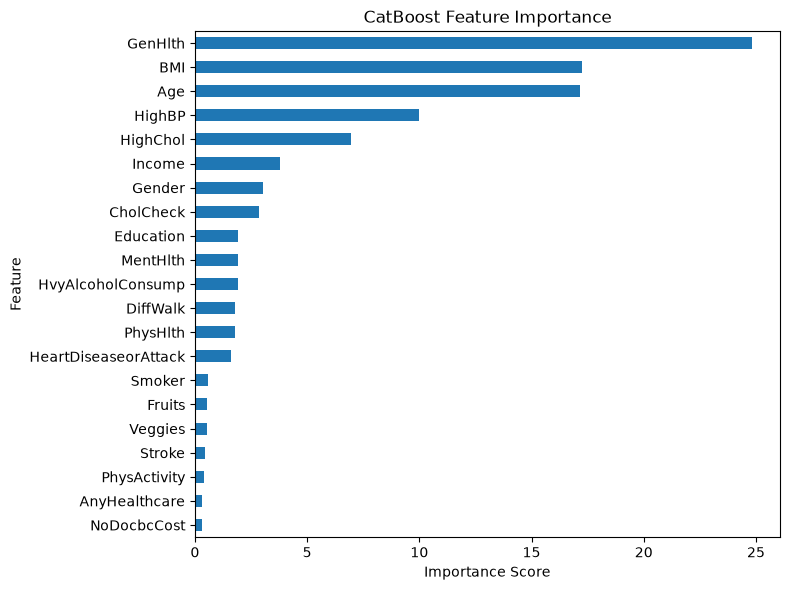

In [22]:
importance = pd.Series(
    cat_final.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(8, 6))

importance.plot(kind="barh")

plt.title("CatBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Most Important Features

In [23]:
importance = pd.Series(
    cat_final.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

GenHlth                 24.828982
BMI                     17.251427
Age                     17.154324
HighBP                   9.976511
HighChol                 6.956700
Income                   3.813063
Gender                   3.055777
CholCheck                2.860466
Education                1.937259
MentHlth                 1.927061
HvyAlcoholConsump        1.924388
DiffWalk                 1.793864
PhysHlth                 1.791614
HeartDiseaseorAttack     1.609059
Smoker                   0.583647
Fruits                   0.539036
Veggies                  0.539020
Stroke                   0.469240
PhysActivity             0.383439
AnyHealthcare            0.303704
NoDocbcCost              0.301419
dtype: float64


# Discussion

**The most influential predictors were:**
- High Blood Pressure
- General Health Status
- High Cholesterol
- Age
- Body Mass Index

# Conclusion

This project demonstrated the application of multiple machine learning algorithms to a healthcare classification problem.

## Key Findings

- CatBoost achieved the highest validation accuracy among all evaluated models.
- Hyperparameter tuning improved model performance.
- Threshold optimization produced the largest single improvement in classification accuracy.
- Gradient boosting methods outperformed Logistic Regression and Random Forest.
- High Blood Pressure, General Health Status, High Cholesterol, Age, and BMI emerged as the most influential predictors.

## Models Evaluated

| Model | Description |
|---------|---------|
| Logistic Regression | Linear baseline model |
| Random Forest | Bagging ensemble model |
| XGBoost | Gradient boosting model |
| CatBoost | Advanced gradient boosting model |
| CatBoost + XGBoost Ensemble | Ensemble model combining probability predictions |

## Lessons Learned

This project provided hands-on experience with:

- Cross-validation
- Hyperparameter tuning
- Grid Search and Randomized Search
- Regularization
- Ensemble learning
- Gradient Boosting
- Feature Importance Analysis
- Threshold Optimization
- Model Evaluation and Selection

Overall, CatBoost with optimized hyperparameters and threshold selection provided the strongest performance for diabetes prediction within this dataset.

---

- Author: Farshad Parsayan
- Date: 18 October 2026